In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster  import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
X,y = make_blobs(n_samples=500,centers=3,random_state=42,cluster_std=4)
df = pd.DataFrame(X,columns = ['feature 1','feature 2'])
df

,feature 1,feature 2
0,-2.282534,-9.692815
1,-6.147668,1.755990
2,13.399091,-1.260023
3,-4.077630,3.160226
4,9.444735,0.340868
...,...,...
495,-1.282205,-3.181575
496,-2.817604,10.378894
497,3.296740,8.649256
498,-8.970519,-2.684073


In [ ]:
X_scaled = scaler.fit_transform(X)


In [ ]:
wcss = []
for k in range(1,11):
  kmeans = KMeans(n_clusters=k,random_state=42)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)

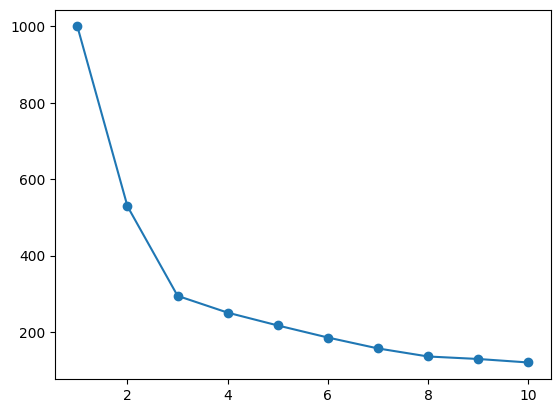

In [ ]:
plt.plot(range(1,11),wcss,marker = 'o')


<Axes: xlabel='feature 1', ylabel='feature 2'>

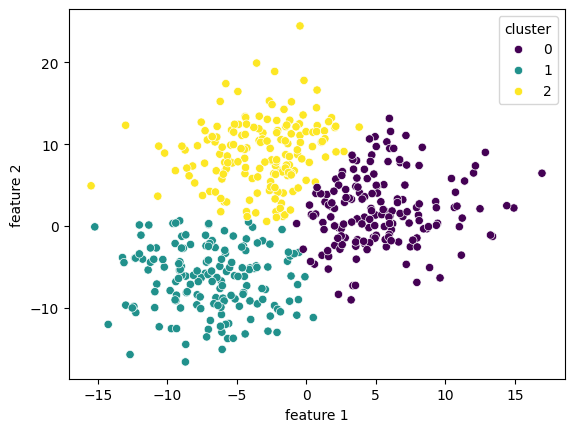

In [ ]:
kmeans_final = KMeans(n_clusters=3,random_state=42)
cluster_labels = kmeans_final.fit_predict(X_scaled)
df['cluster'] = cluster_labels
sns.scatterplot(x = df['feature 1'],
                y = df['feature 2'],
                hue = df['cluster'],
                palette= 'viridis')



In [ ]:
from sklearn.datasets import make_moons
X,y = make_moons(n_samples = 500 , noise = 0.05, random_state=42)


In [ ]:
from sklearn.cluster import KMeans,DBSCAN
df = pd.DataFrame(X,columns =  ['Feature_1','Feature_2'])

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)


In [ ]:
kmeans = KMeans(n_clusters=3,random_state=42)
kmeans_label = kmeans.fit_predict(X_scaled)
df['kmeans_cluster'] = kmeans_label

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

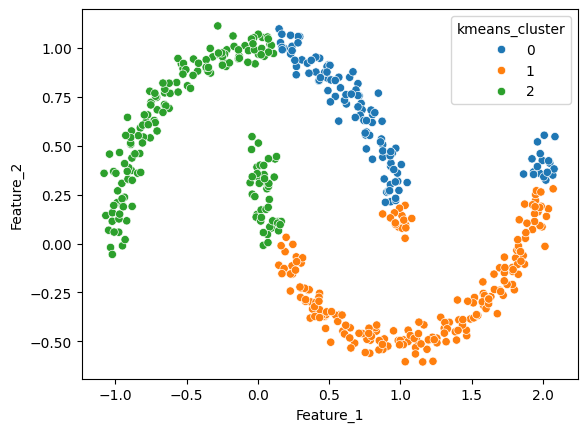

In [ ]:
sns.scatterplot(x = df['Feature_1'],y = df['Feature_2'],hue = df['kmeans_cluster'],palette = 'tab10')

In [ ]:
dbscan = DBSCAN(eps = 0.3,min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

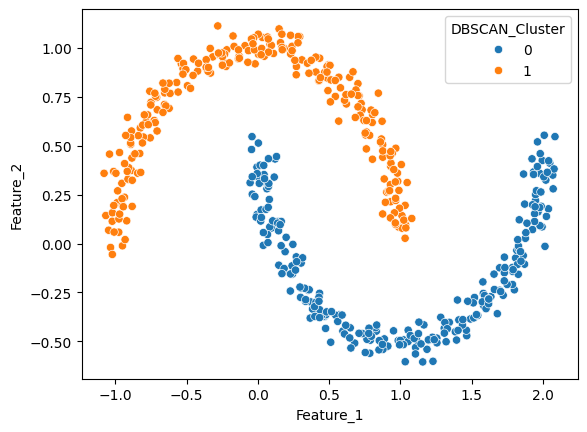

In [ ]:
df['DBSCAN_Cluster'] = dbscan_labels
sns.scatterplot(x = df['Feature_1'],y = df['Feature_2'],hue = df['DBSCAN_Cluster'],palette= 'tab10')
